In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df = pd.read_excel("Sample - Superstore 2.xlsx")

In [10]:
print(df.head())

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  FUR-BO-10

In [11]:
print(df.shape)

(9994, 21)


In [12]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [13]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [14]:
print(df.describe())

            Row ID                     Order Date  \
count  9994.000000                           9994   
mean   4997.500000  2016-04-30 00:07:12.259355648   
min       1.000000            2014-01-03 00:00:00   
25%    2499.250000            2015-05-23 00:00:00   
50%    4997.500000            2016-06-26 00:00:00   
75%    7495.750000            2017-05-14 00:00:00   
max    9994.000000            2017-12-30 00:00:00   
std    2885.163629                            NaN   

                           Ship Date   Postal Code         Sales     Quantity  \
count                           9994   9994.000000   9994.000000  9994.000000   
mean   2016-05-03 23:06:58.571142912  55190.379428    229.858001     3.789574   
min              2014-01-07 00:00:00   1040.000000      0.444000     1.000000   
25%              2015-05-27 00:00:00  23223.000000     17.280000     2.000000   
50%              2016-06-29 00:00:00  56430.500000     54.490000     3.000000   
75%              2017-05-18 00:00:00

In [15]:
df = df[['Quantity', 'Discount', 'Category',
         'Sub-Category', 'Region', 'Segment',
         'Ship Mode', 'Sales']]

In [16]:
print(df.head())

   Quantity  Discount         Category Sub-Category Region    Segment  \
0         2      0.00        Furniture    Bookcases  South   Consumer   
1         3      0.00        Furniture       Chairs  South   Consumer   
2         2      0.00  Office Supplies       Labels   West  Corporate   
3         5      0.45        Furniture       Tables  South   Consumer   
4         2      0.20  Office Supplies      Storage  South   Consumer   

        Ship Mode     Sales  
0    Second Class  261.9600  
1    Second Class  731.9400  
2    Second Class   14.6200  
3  Standard Class  957.5775  
4  Standard Class   22.3680  


In [19]:
X = df[['Quantity', 'Discount', 'Category',
        'Sub-Category', 'Region', 'Segment',
        'Ship Mode']]

y = df['Sales']

In [20]:
X = pd.get_dummies(X, drop_first=True)

In [21]:
print(X.head())

   Quantity  Discount  Category_Office Supplies  Category_Technology  \
0         2      0.00                     False                False   
1         3      0.00                     False                False   
2         2      0.00                      True                False   
3         5      0.45                     False                False   
4         2      0.20                      True                False   

   Sub-Category_Appliances  Sub-Category_Art  Sub-Category_Binders  \
0                    False             False                 False   
1                    False             False                 False   
2                    False             False                 False   
3                    False             False                 False   
4                    False             False                 False   

   Sub-Category_Bookcases  Sub-Category_Chairs  Sub-Category_Copiers  ...  \
0                    True                False                 False 

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [23]:
model = LinearRegression()

In [24]:
model.fit(X_train, y_train)

LinearRegression()

In [25]:
y_pred = model.predict(X_test)

In [26]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 226.3129135395645
MSE: 480699.65019409236
RMSE: 693.325068199681
R2 Score: 0.1862191781164858


In [27]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print(comparison.head(10))

   Actual Sales  Predicted Sales
0       563.808       234.682930
1        36.672        62.730134
2        37.300        73.290889
3       212.058       455.166782
4       171.288       592.079685
5        99.136        27.189833
6       340.182       247.718384
7        17.380       177.598368
8        22.620      -108.007546
9        71.632       351.000021


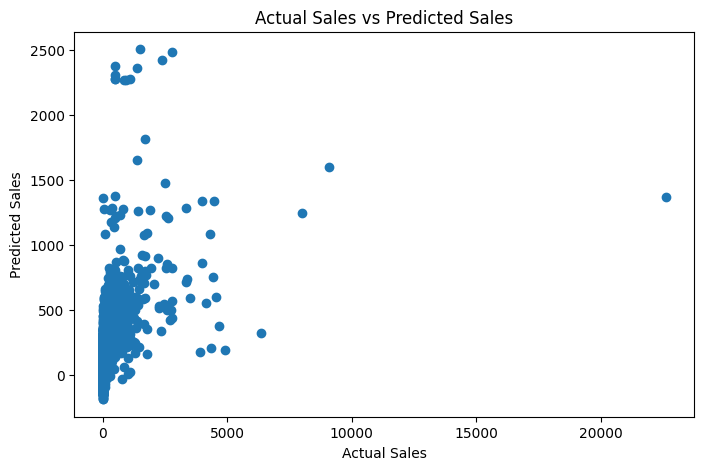

In [28]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title("Actual Sales vs Predicted Sales")

plt.show()

In [29]:
print("Sales Prediction Project")
print("------------------------")

print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Sales Prediction Project
------------------------
Total Records: 9994
Training Records: 7995
Testing Records: 1999
MAE: 226.3129135395645
RMSE: 693.325068199681
R2 Score: 0.1862191781164858


In [5]:
df = df[['Quantity', 'Discount', 'Category',
         'Sub-Category', 'Region', 'Segment',
         'Ship Mode', 'Product Name', 'Product ID',
         'Sales']]

df = df.dropna()

In [6]:
X = df[['Quantity', 'Discount', 'Category',
        'Sub-Category', 'Region', 'Segment',
        'Ship Mode', 'Product Name', 'Product ID']]

y = df['Sales']

In [7]:
X = pd.get_dummies(X, drop_first=True)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
model2 = LinearRegression()

model2.fit(X_train, y_train)

LinearRegression()

In [10]:
y_pred2 = model2.predict(X_test)

In [11]:
mae2 = mean_absolute_error(y_test, y_pred2)

mse2 = mean_squared_error(y_test, y_pred2)

rmse2 = np.sqrt(mse2)

r2_2 = r2_score(y_test, y_pred2)

print("MODEL 2 RESULTS")
print("----------------")

print("MAE:", mae2)
print("MSE:", mse2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)

MODEL 2 RESULTS
----------------
MAE: 158.53758869336542
MSE: 385408.59986814886
RMSE: 620.8128541421713
R2 Score: 0.34753826628532225


In [12]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Model 1': [226.31, 480699.65, 693.33, 0.1862],
    'Model 2': [mae2, mse2, rmse2, r2_2]
})

print(comparison)

     Metric      Model 1        Model 2
0       MAE     226.3100     158.537589
1       MSE  480699.6500  385408.599868
2      RMSE     693.3300     620.812854
3  R2 Score       0.1862       0.347538
